# TPE · EPA Fuel Economy 2025
## 1. Análisis exploratorio inicial

Se examinan la estructura, los atributos, las distribuciones, los valores faltantes y los valores extremos de la base. El objetivo es comprender los datos antes de realizar la limpieza y plantear las hipótesis.

### 1.1. Contexto y lectura de los datos

El conjunto contiene resultados de ensayos de vehículos de año modelo 2025 realizados por la Environmental Protection Agency (EPA) de Estados Unidos y por fabricantes que reportan sus resultados al organismo. Estos ensayos forman parte del proceso de determinación de las estimaciones oficiales de economía de combustible.

La economía de combustible indica la distancia recorrida por unidad de combustible. En MPG, un valor mayor representa una mayor eficiencia. El año modelo no equivale a la fecha en que se realizó cada ensayo.

Se lee la hoja `Sheet1` del Excel original, conservado en `data/`. Se muestran las primeras filas y un resumen de las columnas para comprobar que la lectura sea correcta.

In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt

archivo = "data/25-testcar-2026-01-21.xlsx"
datos = pd.read_excel(archivo, sheet_name='Sheet1')

print('Filas:', datos.shape[0], '| Columnas:', datos.shape[1])
print(datos.head())
datos.info()

Filas: 4287 | Columnas: 67
   Model Year Vehicle Manufacturer Name Veh Mfr Code  \
0        2025              aston martin          ASX   
1        2025              aston martin          ASX   
2        2025              aston martin          ASX   
3        2025              aston martin          ASX   
4        2025              aston martin          ASX   

  Represented Test Veh Make Represented Test Veh Model Test Vehicle ID  \
0              Aston Martin                    DB12 V8      5723PT5601   
1              Aston Martin                    DB12 V8      5723PT5601   
2              Aston Martin                    DBX 707      8841PT8473   
3              Aston Martin                    DBX 707      8841PT8473   
4              Aston Martin                   Vanquish       370TT7334   

   Test Veh Configuration #  Test Veh Displacement (L)  \
0                         0                        4.0   
1                         0                        4.0   
2                

### 1.2. Unidad de observación y repeticiones

Cada fila corresponde al registro de un ensayo de una configuración. La combinación `Veh Mfr Code`, `Test Vehicle ID` y `Test Veh Configuration #` identifica una configuración. Un mismo vehículo puede tener varias configuraciones y ensayos, por lo que no se debe interpretar la cantidad de filas como cantidad de vehículos diferentes.

Se cuentan las configuraciones y los ensayos distintos y se comprueba si existen filas completamente duplicadas.

In [7]:
clave_config = ['Veh Mfr Code', 'Test Vehicle ID', 'Test Veh Configuration #']

print('Configuraciones distintas:', datos[clave_config].drop_duplicates().shape[0])
print('Números de ensayo distintos:', len(datos['Test Number'].value_counts()))
print('Filas completamente duplicadas:', datos.duplicated().sum())

# Mostramos un ejemplo de un mismo ensayo registrado en más de una fila.
repetidos = datos[datos['Test Number'].duplicated(keep=False)]
ejemplo = repetidos['Test Number'].iloc[0]
columnas = ['Test Number'] + clave_config + ['Test Category', 'Aftertreatment Device Desc']
print(datos.loc[datos['Test Number'] == ejemplo, columnas])

Configuraciones distintas: 1448
Números de ensayo distintos: 4014
Filas completamente duplicadas: 0
     Test Number Veh Mfr Code Test Vehicle ID  Test Veh Configuration #  \
12  SBMX10086268          BMX         8D89453                         0   
13  SBMX10086268          BMX         8D89453                         0   

   Test Category Aftertreatment Device Desc  
12           FTP                      Other  
13           FTP         Three-way catalyst  


La base contiene **4.287 registros, 1.448 configuraciones y 4.014 números de ensayo distintos**. No hay filas completamente idénticas. El ejemplo muestra un ensayo repetido con distinto dispositivo de postratamiento: repetir el número de ensayo no equivale a tener filas idénticas.

Las filas se conservan durante la exploración. El tratamiento de las repeticiones y la unidad de análisis deberán definirse antes de los análisis posteriores, porque algunos ensayos aparecen más veces que otros.

### 1.3. Caracterización de los atributos

Las 67 columnas incluyen identificadores, categorías, características técnicas, condiciones de ensayo y resultados. Se distinguen los tipos computacionales que muestra `info()` de su significado estadístico.

| Grupo | Ejemplos de atributos | Tipo e interpretación |
| --- | --- | --- |
| Identificación | `Veh Mfr Code`, `Test Vehicle ID`, `Test Veh Configuration #`, `Test Number` | Identifican fabricantes, vehículos, configuraciones y ensayos; no son medidas para promediar. |
| Año modelo | `Model Year` | Variable temporal discreta; toma el valor 2025 en toda la base. |
| Características cualitativas | Fabricante, modelo, `Vehicle Type`, transmisión, tracción y combustible | Variables nominales. Los códigos numéricos también representan categorías. |
| Conteos | `# of Cylinders and Rotors`, `# of Gears` | Variables cuantitativas discretas. |
| Características mecánicas | Cilindrada, potencia y peso equivalente | Medidas cuantitativas, expresadas en L, HP y lb. |
| Condiciones y métodos | Procedimiento, categoría, origen del ensayo, indicadores ADFE y promediado | Categorías y campos que describen cómo se obtuvo el resultado. |
| Economía de combustible | `RND_ADJ_FE`, `FE Bag 1` a `FE Bag 4` | Medidas cuantitativas; `FE_UNIT` declara MPG en todos los registros. |
| Emisiones | THC, CO, CO2, NOx, PM, CH4 y N2O | Medidas cuantitativas expresadas en g/mi. |
| Otros parámetros | Relaciones mecánicas, coeficientes del dinamómetro, postratamiento y ponderación | Información técnica complementaria; algunos campos solo corresponden a ciertos tipos de ensayo. |

Para describir la composición de la base se muestran las frecuencias de las categorías principales. Los porcentajes se calculan sobre el total de registros, incluyendo las ausencias.

Vehicle Type
              Registros  Porcentaje
Vehicle Type                       
Truck              2030       47.35
Car                1631       38.05
Both                626       14.60
----------------------------------------
Test Fuel Type Description
                                               Registros  Porcentaje
Test Fuel Type Description                                          
Tier 2 Cert Gasoline                                3236       75.48
Electricity                                          654       15.26
Cold CO Regular (Tier 2)                             160        3.73
Federal Cert Diesel 7-15 PPM Sulfur                  150        3.50
Cold CO Premium (Tier 2)                              57        1.33
E85 (85% Ethanol 15% EPA Unleaded Gasoline)           12        0.28
Hydrogen 5                                            10        0.23
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)          3        0.07
Cold CO E10 Regular Gasoline (Tier 3)            

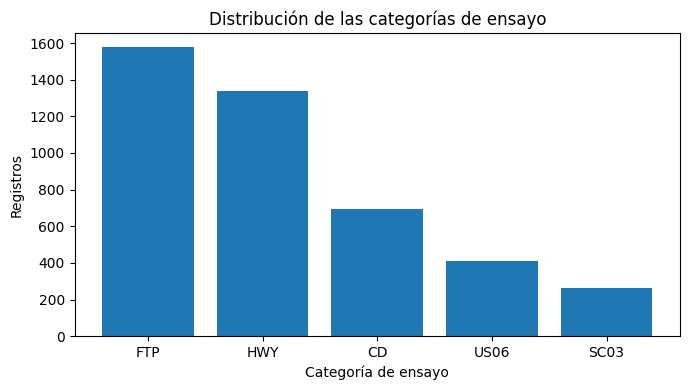

In [8]:
categoricas = ['Vehicle Type', 'Test Fuel Type Description', 'Test Category',
               'Drive System Description', 'Tested Transmission Type']

for columna in categoricas:
    frecuencias = datos[columna].value_counts(dropna=False)
    tabla = pd.DataFrame({
        'Registros': frecuencias,
        'Porcentaje': 100 * frecuencias / len(datos)
    })
    print(columna)
    print(tabla.round(2))
    print("-" * 40)

frecuencias_cat = datos['Test Category'].value_counts()
plt.figure(figsize=(7, 4))
plt.bar(frecuencias_cat.index, frecuencias_cat.values)
plt.xlabel('Categoría de ensayo')
plt.ylabel('Registros')
plt.title('Distribución de las categorías de ensayo')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Predominan `Tier 2 Cert Gasoline` (**3.236 registros**), `Truck` (**2.030**) y las categorías de ensayo `FTP` (**1.577**) y `HWY` (**1.340**). Estas frecuencias describen los registros disponibles, no el parque automotor ni las ventas de vehículos.

### 1.4. Valores nulos

Se calcula la cantidad y el porcentaje de faltantes por columna. Un cero es un valor registrado y se diferencia de una ausencia. Luego se revisan dos patrones relevantes: la disponibilidad de información ADFE según el método y la ausencia de cilindros según el combustible.

In [9]:
faltantes = pd.DataFrame({
    'Nulos': datos.isna().sum(),
    'Porcentaje': 100 * datos.isna().sum() / len(datos)
})
print(faltantes[faltantes['Nulos'] > 0].sort_values('Nulos', ascending=False).round(2))

# Los campos ADFE corresponden a economía derivada analíticamente.
adfe = ['ADFE Test Number', 'ADFE Total Road Load HP',
        'ADFE Equiv. Test Weight (lbs.)', 'ADFE N/V Ratio']
print('Porcentaje de nulos ADFE según el método:')
print(datos[adfe].isna().groupby(datos['Analytically Derived FE?']).mean() * 100)

print('Nulos en cilindros según combustible:')
nulos_cilindros = datos['# of Cylinders and Rotors'].isna()
print(nulos_cilindros.groupby(datos['Test Fuel Type Description']).sum())

                                Nulos  Porcentaje
Averaging Group ID               4212       98.25
Averaging Weighting Factor       4212       98.25
ADFE Test Number                 4075       95.05
ADFE Total Road Load HP          4075       95.05
ADFE Equiv. Test Weight (lbs.)   4075       95.05
ADFE N/V Ratio                   4075       95.05
FE Bag 4                         3899       90.95
PM (g/mi)                        3898       90.93
FE Bag 3                         2834       66.11
FE Bag 1                         2423       56.52
FE Bag 2                         2423       56.52
N2O (g/mi)                       2063       48.12
CH4 (g/mi)                       1122       26.17
THC (g/mi)                        958       22.35
NOx (g/mi)                        885       20.64
CO (g/mi)                         884       20.62
CO2 (g/mi)                        724       16.89
DT-Absolute Speed Change Ratg     695       16.21
DT-Energy Economy Rating          695       16.21


Las cuatro columnas ADFE tienen **4.075 nulos cada una (95,05%)**, todos en registros que no usan el método analíticamente derivado. Los **212 registros** que sí lo usan tienen esos campos completos. Por lo tanto, no toda ausencia equivale a un dato perdido que deba completarse.

En cilindros hay **670 nulos**: 654 corresponden a `Electricity`, 10 a `Hydrogen 5` y 6 a gasolina. La concentración por combustible sugiere diferencias de aplicabilidad; los casos de gasolina requieren revisión. `RND_ADJ_FE` presenta **221 nulos (5,16%)**. Las demás ausencias quedan identificadas en la tabla para su evaluación durante la limpieza.

### 1.5. Distribuciones y estadística descriptiva

Se estudian seis variables centrales para el trabajo: cilindrada, potencia, cilindros, marchas, peso y economía de combustible. `describe()` muestra la cantidad de valores disponibles, media, desvío estándar, mínimo, cuartiles y máximo. Los histogramas permiten observar la forma de las distribuciones.

Se excluyen códigos e identificadores del resumen numérico, aunque estén almacenados como números.

       Test Veh Displacement (L)  Rated Horsepower  # of Cylinders and Rotors  \
count                   4287.000          4287.000                   3617.000   
mean                       4.688           340.698                      5.222   
std                       14.572           175.122                      1.624   
min                        0.001             1.000                      3.000   
25%                        1.991           201.000                      4.000   
50%                        2.487           305.000                      4.000   
75%                        3.000           409.000                      6.000   
max                       99.999          1948.000                     16.000   

       # of Gears  Equivalent Test Weight (lbs.)  RND_ADJ_FE  
count    4287.000                       4287.000    4066.000  
mean        6.052                       4818.784      64.962  
std         3.398                        985.818     456.941  
min         1.000 

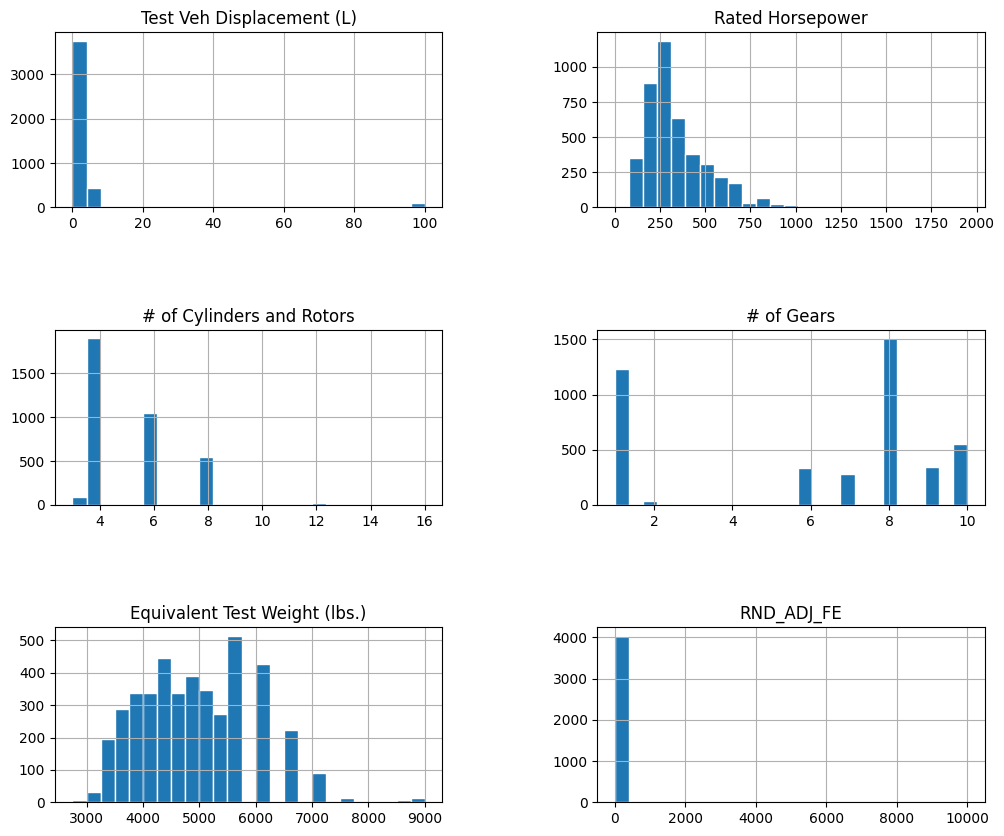

In [11]:
principales = ['Test Veh Displacement (L)', 'Rated Horsepower', '# of Cylinders and Rotors',
               '# of Gears', 'Equivalent Test Weight (lbs.)', 'RND_ADJ_FE']
etiquetas = ['Cilindrada (L)', 'Potencia (HP)', 'Cilindros o rotores',
             'Cantidad de marchas', 'Peso equivalente (lb)', 'Economía declarada (MPG)']

print(datos[principales].describe().round(3))

datos[principales].hist(figsize=(12, 10), bins=25, edgecolor='white')
plt.subplots_adjust(hspace=0.7, wspace=0.4)
plt.show()

El peso equivalente tiene mediana **4.750 lb** y varía entre **2.750 y 9.000 lb**. La potencia tiene mediana **305 HP**, con mínimo **1 HP** y máximo **1.948 HP**. La cilindrada tiene mediana **2,487 L** y máximo **99,999 L**.

La economía tiene mediana **32,9 MPG** y media aproximada **65,0 MPG**. Los valores extremos y la mezcla de combustibles y procedimientos afectan el resumen global; el histograma completo muestra esos extremos, aunque comprima la zona central.

Para observar la economía en un grupo más comparable, se seleccionan los registros de gasolina Tier 2 y un único procedimiento: `Federal fuel 2-day exhaust (w/can load)`. Esta selección crea una vista descriptiva y no modifica la base original.

Registros seleccionados: 922
       Economía (MPG)
count         922.000
mean           29.734
std            11.574
min             9.500
25%            22.500
50%            26.600
75%            33.475
max            82.800


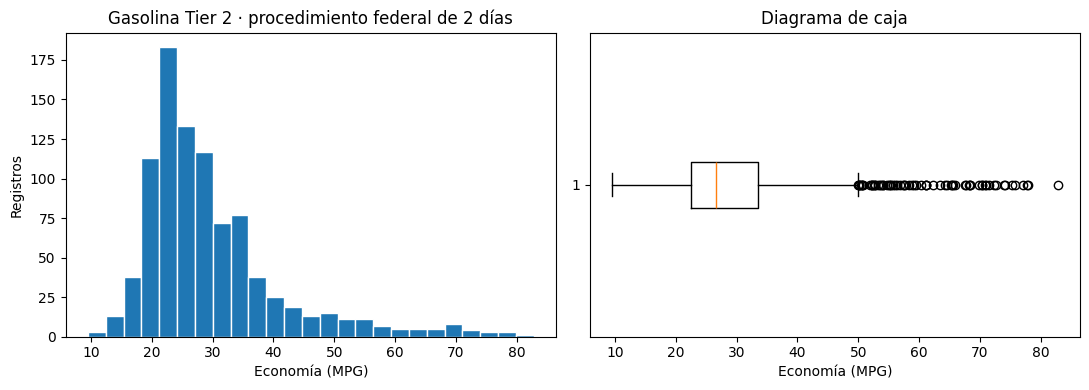

In [12]:
# Seleccionamos un grupo específico para aislar la economía (gasolina Tier 2 y procedimiento federal)
seleccion = (
    (datos['Test Fuel Type Description'] == 'Tier 2 Cert Gasoline') &
    (datos['Test Procedure Description'] == 'Federal fuel 2-day exhaust (w/can load)')
)
contexto = datos.loc[seleccion].copy()
economia = contexto['RND_ADJ_FE'].dropna()

print('Registros seleccionados:', len(contexto))
print(economia.describe().to_frame('Economía (MPG)').round(3))

# Gráficos de distribución y boxplot para el subgrupo
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(economia, bins=25, edgecolor='white')
axes[0].set_xlabel('Economía (MPG)')
axes[0].set_ylabel('Registros')
axes[0].set_title('Gasolina Tier 2 · procedimiento federal de 2 días')

axes[1].boxplot(economia, vert=False)
axes[1].set_xlabel('Economía (MPG)')
axes[1].set_title('Diagrama de caja')
plt.tight_layout()
plt.show()

La selección contiene **922 registros**, con media **29,734 MPG**, mediana **26,6 MPG**, Q1 **22,5 MPG**, Q3 **33,475 MPG** y máximo **82,8 MPG**. El histograma presenta una cola hacia valores altos. Los resúmenes cambian al fijar combustible y procedimiento, lo que justifica considerar ese contexto antes de comparar economías.

### 1.6. Valores extremos

El diagrama de caja señala posibles valores atípicos usando los límites **Q1 − 1,5 × RIC** y **Q3 + 1,5 × RIC**, donde **RIC = Q3 − Q1**. Los bigotes llegan hasta los valores observados más alejados dentro de esos límites. Los puntos exteriores son candidatos a revisión; no son errores confirmados.

Se aplica el criterio al grupo anterior para evitar que la mezcla de ensayos determine los límites. También se muestran las mayores economías de toda la base y se cuentan otros valores llamativos observados durante la exploración.

In [13]:
q1 = economia.quantile(0.25)
q3 = economia.quantile(0.75)
ric = q3 - q1
limite_inferior = q1 - 1.5 * ric
limite_superior = q3 + 1.5 * ric
atipicos = economia[(economia < limite_inferior) | (economia > limite_superior)]
print('Límites del diagrama de caja:', round(limite_inferior, 3), round(limite_superior, 3))
print('Registros candidatos a atípicos en el grupo:', len(atipicos))

columnas_revision = ['Represented Test Veh Model', 'Test Fuel Type Description',
                     'Test Category', 'RND_ADJ_FE']
print(datos.sort_values(by='RND_ADJ_FE', ascending=False)[columnas_revision].head(10))

print('Registros con cilindrada 99.999 L:', (datos['Test Veh Displacement (L)'] == 99.999).sum())
print('Economías iguales al máximo de la base:', (datos['RND_ADJ_FE'] == datos['RND_ADJ_FE'].max()).sum())
print('Economías iguales a cero:', (datos['RND_ADJ_FE'] == 0).sum())
print('Potencias iguales a 1 HP:', (datos['Rated Horsepower'] == 1).sum())
print('Combustibles de los registros con cilindrada 99.999 L:')
print(datos.loc[datos['Test Veh Displacement (L)'] == 99.999,
                 'Test Fuel Type Description'].value_counts())

Límites del diagrama de caja: 6.037 49.938
Registros candidatos a atípicos en el grupo: 68
     Represented Test Veh Model  \
3021                     Utopia   
3022                     Utopia   
2462                      Emira   
2466                      Emira   
2465                      Emira   
2464                      Emira   
2463                      Emira   
2461                      Emira   
3466                       RC F   
3460                       RC F   

                         Test Fuel Type Description Test Category  RND_ADJ_FE  
3021                 CARB LEV3 E10 Premium Gasoline           FTP     10000.0  
3022                 CARB LEV3 E10 Premium Gasoline           HWY     10000.0  
2462  Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)          SC03     10000.0  
2466          Cold CO E10 Regular Gasoline (Tier 3)           FTP     10000.0  
2465                 CARB LEV3 E10 Regular Gasoline          SC03     10000.0  
2464  Tier 3 E10 Regular Gasoline (9 RVP @L

En el grupo de gasolina y procedimiento común se identifican **68 registros candidatos a atípicos**, con límites aproximados de **6,04 y 49,94 MPG**. Son observaciones para revisar y no registros que deban eliminarse automáticamente.

Hay **95 registros con cilindrada 99,999 L**, todos asociados a electricidad. También se observan **8 economías iguales al máximo 9999.9999999**, dos economías de **4599,1 y 4595,3**, **2 economías cero** y **8 potencias de 1 HP**.

Estos valores requieren verificar si corresponden a convenciones de registro, resultados particulares o inconsistencias. En esta etapa se señalan sin corregirlos ni eliminarlos. Tampoco se eliminan los candidatos identificados por el diagrama de caja.

### 1.7. Conclusiones del inciso 1

La base tiene **4.287 filas y 67 atributos**, con **1.448 configuraciones** y distintos tipos de ensayo. No hay filas idénticas, pero un ensayo o una configuración puede aparecer en más de una fila. Por eso, el tratamiento de las repeticiones debe definirse antes de los análisis posteriores.

Los faltantes dependen en parte del tipo de registro. El caso ADFE muestra que una ausencia puede corresponder a un método que no se utiliza. Otras ausencias requieren revisión, especialmente cuando no se explican por la aplicabilidad del atributo.

Las variables principales presentan distribuciones y extremos que deben interpretarse con el combustible y el procedimiento de ensayo. La economía global resulta afectada por valores muy altos; al considerar gasolina Tier 2 y un procedimiento común, la mediana es **26,6 MPG**.

La exploración deja identificadas las cuestiones para el inciso 2: repeticiones, ausencias y valores extremos. **El Excel original y los valores del DataFrame se conservaron sin correcciones ni imputaciones.**

## 2. Limpieza de la base

Pendiente de desarrollo. Se registrarán las acciones implementadas, su justificación y el efecto sobre los datos.

## 3. Hipótesis propuestas

Pendiente de desarrollo. Se formularán una hipótesis univariada, una bivariada y una multivariada, con su justificación de dominio.

## 4. Validación de hipótesis

Pendiente de desarrollo. Se evaluarán las tres hipótesis propuestas y las tres indicadas en el enunciado. Para cada una se presentarán la técnica elegida, sus condiciones de aplicación, los resultados y la conclusión.